# 10 · Cost–benefit of the screening threshold
Why recall ≥ 80 %? Make the decision explicit. A person flagged gets a confirmatory test (cost `c`); a diabetic person who is not flagged is a missed case (cost `M`). The real costs are unknown, so we study the **ratio M / c** and show which threshold each ratio implies. Model: reduced LightGBM; thresholds chosen on validation, results on test.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap, warnings
from functools import partialmethod
from tqdm import tqdm; tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
from src.preprocess import get_splits
from src.evaluation import threshold_for_recall
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
red = joblib.load("../models/lightgbm_reduced.joblib")
keep = [c for c in X_tr.columns if c not in ["CholCheck", "HvyAlcoholConsump", "AnyHealthcare"]]
pv, pt = red.predict_proba(X_va[keep])[:, 1], red.predict_proba(X_te[keep])[:, 1]
yv, yt = y_va.values, y_te.values
ts = np.linspace(0.01, 0.9, 890)
def cost_curve(p, y, M, c=1.0):            # expected cost per person
    return np.array([c * (p >= t).mean() + M * ((p < t) & (y == 1)).mean() for t in ts])
thr_ref = threshold_for_recall(y_va, pv, 0.80)
print(f"reference screening threshold (recall >= 80 % on validation): {thr_ref:.3f}")
print(f"For a calibrated score, flag iff p >= c/M. So this threshold implies M/c = 1/{thr_ref:.3f} = {1/thr_ref:.1f}: a missed case is valued about {1/thr_ref:.0f} confirmatory tests.")

reference screening threshold (recall >= 80 % on validation): 0.147
For a calibrated score, flag iff p >= c/M. So this threshold implies M/c = 1/0.147 = 6.8: a missed case is valued about 7 confirmatory tests.


## 1. Optimal threshold for different cost ratios
`cost per 1,000 people` = 1,000 × (flag rate × c + missed-case rate × M), c = 1. Baselines: *test nobody* (cost = 1,000 × prevalence × M) and *test everybody* (cost = 1,000 × c).

In [3]:
rows = []
for M_ in [2, 5, 7, 10, 20, 50, 100]:
    t_opt = ts[np.argmin(cost_curve(pv, yv, M_))]; yhat = pt >= t_opt
    cost = 1000 * (yhat.mean() + M_ * ((~yhat) & (yt == 1)).mean())
    rows.append({"M/c": M_, "optimal threshold (val)": t_opt, "recall": recall_score(yt, yhat), "precision": precision_score(yt, yhat), "flagged": yhat.mean(),
                 "cost /1000 (model)": cost, "cost /1000 (test nobody)": 1000 * yt.mean() * M_, "cost /1000 (test everybody)": 1000.0})
tab = pd.DataFrame(rows).round(3); tab

,M/c,optimal threshold (val),recall,precision,flagged,cost /1000 (model),cost /1000 (test nobody),cost /1000 (test everybody)
0,2,0.473,0.196,0.560,0.054,299.460,305.909,1000.0
1,5,0.211,0.663,0.363,0.280,537.389,764.773,1000.0
2,7,0.138,0.814,0.302,0.412,611.644,1070.682,1000.0
3,10,0.096,0.893,0.267,0.512,675.556,1529.545,1000.0
4,20,0.053,0.955,0.224,0.652,789.582,3059.090,1000.0
5,50,0.021,0.988,0.186,0.814,908.489,7647.725,1000.0
6,100,0.014,0.995,0.175,0.871,951.862,15295.451,1000.0


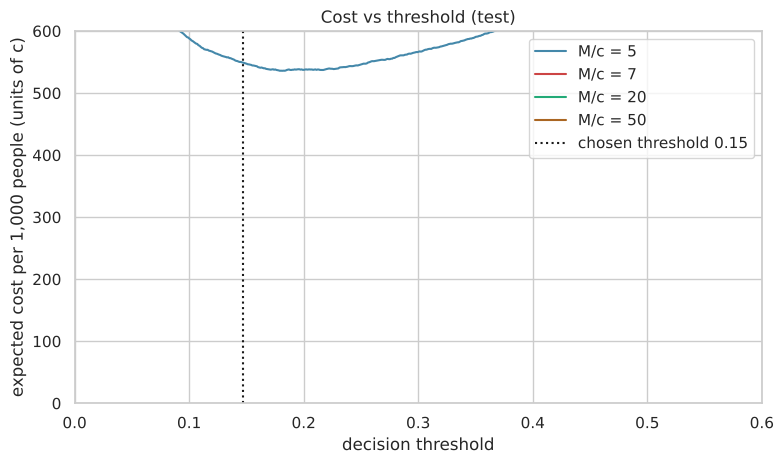

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for M_, c in zip([5, 7, 20, 50], ["#48a", "#c44", "#2a7", "#a62"]):
    ax.plot(ts, cost_curve(pt, yt, M_) * 1000, c=c, label=f"M/c = {M_}")
ax.axvline(thr_ref, c="k", ls=":", label=f"chosen threshold {thr_ref:.2f}"); ax.set_xlim(0, 0.6); ax.set_ylim(0, 600)
ax.set_xlabel("decision threshold"); ax.set_ylabel("expected cost per 1,000 people (units of c)"); ax.legend(); ax.set_title("Cost vs threshold (test)")
plt.tight_layout(); plt.savefig("../figures/cost_threshold.png", dpi=150); plt.show()

## 2. Decision curve analysis (net benefit)
`NB(t) = TP/n − FP/n × t/(1−t)` (Vickers & Elkin). Compares the model with *flag everybody* and *flag nobody* across thresholds `t`, where `t/(1−t)` plays the role of the cost ratio c/(M−c). A model is useful where its curve is above both baselines.

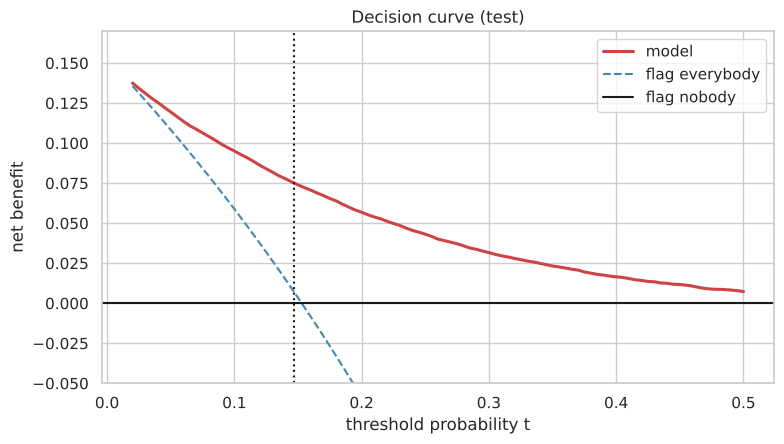

at t = 0.14: net benefit model 0.076 vs flag-everybody 0.009


In [5]:
tg = np.linspace(0.02, 0.5, 97)
nb_model = [((pt >= t) & (yt == 1)).mean() - ((pt >= t) & (yt == 0)).mean() * t / (1 - t) for t in tg]
nb_all = [yt.mean() - (1 - yt.mean()) * t / (1 - t) for t in tg]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(tg, nb_model, c="#c44", lw=2.2, label="model"); ax.plot(tg, nb_all, c="#48a", ls="--", label="flag everybody"); ax.axhline(0, c="k", label="flag nobody")
ax.axvline(thr_ref, c="k", ls=":"); ax.set_ylim(-0.05, 0.17); ax.set_xlabel("threshold probability t"); ax.set_ylabel("net benefit"); ax.legend(); ax.set_title("Decision curve (test)")
plt.tight_layout(); plt.savefig("../figures/decision_curve.png", dpi=150); plt.show()
i = np.argmin(np.abs(tg - thr_ref)); print(f"at t = {tg[i]:.2f}: net benefit model {nb_model[i]:.3f} vs flag-everybody {nb_all[i]:.3f}")

## 3. Conclusion
- The 80 %-recall rule is equivalent to saying that a missed case costs about **7× a confirmatory test**. If a programme values a missed case at much more than that, the threshold should go down (more people tested); if testing is expensive relative to a missed case, it should go up.
- The decision-curve shows over which range of thresholds the model beats the two trivial policies.
- These are **hypothetical costs**: the point is to make the trade-off explicit so that the stakeholder can plug in real values.